### Paso 0: Preparación del entorno
Instalamos las librerías necesarias para cuantización y ajuste ligero (`peft`, `bitsandbytes`, `datasets`, `accelerate`) y eliminamos versiones incompatibles de `torchao`.


In [2]:
#  Instalar las librerias (en Colab ya vienen torch y transformers; anadimos el resto)
import importlib.util, importlib.metadata, subprocess, sys
faltan = [p for p in ("peft", "bitsandbytes", "datasets", "accelerate") if importlib.util.find_spec(p) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=False)
# Colab trae de serie una version antigua de torchao que hace fallar a peft al fusionar el adapter. No la usamos: fuera.
try:
    v = importlib.metadata.version("torchao")
    if tuple(int(x) for x in v.split(".")[:2]) < (0, 16):
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
        print(f"torchao {v} desinstalado (incompatible con peft)")
except importlib.metadata.PackageNotFoundError:
    pass
print("Librerias listas")

Librerias listas


### Paso 1: Creación del dataset y función validadora
Definimos 18 ejemplos propios de gestión de alquileres con una estructura estricta de 5 líneas (titular, 3 viñetas con guion y firma fija), además de 4 preguntas de prueba inéditas y una función para validar automáticamente el formato.


In [3]:
import json

EJEMPLOS = [
    {
        "instruccion": "Se ha roto la caldera y no tengo agua caliente",
        "respuesta": "Gestionamos la reparación urgente con el servicio técnico\n- Envía un vídeo breve o foto del código de error que marca la pantalla.\n- Confirmaremos si la avería corresponde al seguro o al propietario.\n- El técnico contactará contigo hoy mismo para acordar la visita.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Quiero saber cuándo me devuelven la fianza al dejar el piso",
        "respuesta": "La fianza se liquida tras revisar el estado de la vivienda\n- Realizaremos la inspección final el mismo día de la entrega de llaves.\n- Comprobaremos que no existan desperfectos ni facturas de suministros pendientes.\n- Recibirás la transferencia en tu cuenta en un plazo máximo de treinta días.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Me gustaría adoptar un perro en el piso de alquiler",
        "respuesta": "Debemos revisar la cláusula de mascotas de tu contrato\n- Consulta el apartado de normas de convivencia de tu contrato vigente.\n- Si requiere autorización expresa, solicitaremos el permiso por escrito al propietario.\n- Te confirmaremos la respuesta formal antes de que traigas al animal.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Este mes se me va a retrasar el pago del alquiler dos días",
        "respuesta": "Agradecemos que nos avises con antelación sobre el ingreso\n- Indica la fecha exacta en la que realizarás la transferencia bancaria.\n- Envía el justificante de pago en cuanto quede emitido por tu banco.\n- Ten en cuenta que los retrasos reiterados pueden generar recargos contractuales.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Quiero cambiar la titularidad de la luz y el gas a mi nombre",
        "respuesta": "Facilitamos los datos del inmueble para tramitar el cambio\n- Ten a mano tu contrato de alquiler, tu documento de identidad y tu IBAN.\n- Llama a la comercializadora indicando los códigos CUPS de cada suministro.\n- Envíanos confirmación del alta para cerrar las lecturas anteriores.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Han salido manchas de humedad en el techo del baño",
        "respuesta": "Evaluamos el origen de la filtración para repararla cuanto antes\n- Haz varias fotos nítidas de la zona afectada y compártelas por aquí.\n- Avisaremos al seguro de comunidad por si proviene del vecino superior.\n- Coordinaremos la visita del perito y del pintor una vez seca la pared.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Quiero renovar el contrato de alquiler un año más",
        "respuesta": "Tu contrato se prorroga automáticamente salvo aviso previo\n- Revisa si te corresponde la actualización anual de renta según el índice oficial.\n- Si deseas modificar alguna condición, comunícalo con treinta días de antelación.\n- Te enviaremos el anexo de actualización firmado para tu archivo.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "He perdido las llaves del portal y de la vivienda",
        "respuesta": "Te ayudamos a gestionar una copia o el cambio de cerradura\n- Si necesitas un cerrajero urgente, solicita factura oficial del servicio.\n- Por seguridad, recomendamos sustituir el bombín si las llaves llevaban dirección.\n- Entrega una copia de la nueva llave en nuestra oficina para emergencias.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Quiero pintar las paredes del salón de otro color",
        "respuesta": "Cualquier cambio estético requiere autorización previa del propietario\n- Indícanos el tono exacto y las estancias que te gustaría pintar.\n- Solicitaremos el visto bueno por escrito para evitar problemas futuros.\n- Sin permiso expreso, deberás devolver las paredes al color blanco original.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "El vecino de arriba hace mucho ruido todas las noches",
        "respuesta": "Intermediamos con la comunidad para resolver las molestias\n- Anota los días y horarios en los que se producen los ruidos.\n- Intenta hablar primero cordialmente o avisa a la policía local si es de madrugada.\n- Trasladaremos una queja formal al presidente y al administrador de la finca.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "La lavadora ha dejado de centrifugar y no desagua",
        "respuesta": "Comprueba primero el filtro antes de enviar un técnico\n- Desenchufa la lavadora y vacía el agua residual por el tapón inferior.\n- Limpia posibles monedas, pelusas o restos que obstruyan el desagüe.\n- Si el fallo persiste, enviaremos a un técnico para repararla o sustituirla.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Mi pareja se viene a vivir conmigo al piso",
        "respuesta": "Actualizamos los datos de ocupación para mantener el contrato al día\n- Envíanos una copia de su documento de identidad para registrar su residencia.\n- Si queréis que figure también como cotitular, redactaremos un anexo.\n- Este trámite no modifica el importe mensual de tu renta actual.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Voy a dejar el piso antes de que termine el año de contrato",
        "respuesta": "Revisa el plazo de preaviso para evitar penalizaciones\n- Comunica tu salida por escrito con al menos treinta días de antelación.\n- Comprueba si tu contrato incluye indemnización por desistimiento anticipado.\n- Acordaremos una fecha para revisar la vivienda y firmar la entrega de llaves.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "El aire acondicionado no enfría aunque el aparato enciende",
        "respuesta": "Revisamos si necesita limpieza de filtros o carga de gas\n- Lava los filtros interiores con agua tibia y déjalos secar bien.\n- Comprueba que el mando esté configurado en modo frío y no en ventilador.\n- Si sigue sin enfriar, enviaremos a un instalador autorizado.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Necesito un certificado de pago del alquiler para pedir una ayuda",
        "respuesta": "Emitimos tu historial de recibos abonados en veinticuatro horas\n- Confirma los meses exactos que necesitas incluir en el certificado.\n- Verificaremos que todos los pagos estén conciliados en nuestra contabilidad.\n- Te lo enviaremos firmado en PDF a tu correo electrónico.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Se ha atascado el fregadero de la cocina",
        "respuesta": "Actúa con precaución para no dañar las tuberías\n- Evita verter productos químicos corrosivos que puedan quemar el PVC.\n- Prueba a limpiar el sifón inferior colocando un cubo debajo.\n- Si el atasco es general en la bajante, avisaremos al fontanero de inmediato.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "Quiero subarrendar una habitación que me sobra a un amigo",
        "respuesta": "El subarriendo parcial está prohibido sin consentimiento expreso\n- Revisa la cláusula de cesión y subarriendo de tu contrato de arrendamiento.\n- Cualquier incorporación de terceros debe ser aprobada por el propietario.\n- Incumplir esta norma es motivo legal de resolución del contrato.\n— Equipo de Gestión de Alquileres"
    },
    {
        "instruccion": "No funciona el telefonillo para abrir el portal desde casa",
        "respuesta": "Comprobamos si es un fallo individual o de toda la finca\n- Pregunta a algún vecino si le ocurre el mismo problema en su vivienda.\n- Si falla en todo el edificio, lo notificaremos al administrador de la comunidad.\n- Si es solo tu terminal, enviaremos un electricista a revisarlo.\n— Equipo de Gestión de Alquileres"
    }
]

PRUEBA = [
    "Se ha fundido la vitrocerámica y salta el diferencial",
    "Quiero empadronarme en el piso que acabo de alquilar",
    "El propietario quiere venir a enseñar el piso a futuros inquilinos",
    "Se ha roto una persiana del dormitorio y no sube"
]

# Guardado en formato JSONL
with open("alquiler_preguntas.jsonl", "w", encoding="utf-8") as f:
    for ejemplo in EJEMPLOS:
        f.write(json.dumps(ejemplo, ensure_ascii=False) + "\n")
print(f"{len(EJEMPLOS)} ejemplos guardados en alquiler_preguntas.jsonl; \n{len(PRUEBA)} preguntas de prueba aparte\n")

for e in EJEMPLOS[:2]:
    print("PREGUNTA :", e["instruccion"])
    print("RESPUESTA:", e["respuesta"].replace("\n", "\n           "), "\n")


18 ejemplos guardados en alquiler_preguntas.jsonl; 
4 preguntas de prueba aparte

PREGUNTA : Se ha roto la caldera y no tengo agua caliente
RESPUESTA: Gestionamos la reparación urgente con el servicio técnico
           - Envía un vídeo breve o foto del código de error que marca la pantalla.
           - Confirmaremos si la avería corresponde al seguro o al propietario.
           - El técnico contactará contigo hoy mismo para acordar la visita.
           — Equipo de Gestión de Alquileres 

PREGUNTA : Quiero saber cuándo me devuelven la fianza al dejar el piso
RESPUESTA: La fianza se liquida tras revisar el estado de la vivienda
           - Realizaremos la inspección final el mismo día de la entrega de llaves.
           - Comprobaremos que no existan desperfectos ni facturas de suministros pendientes.
           - Recibirás la transferencia en tu cuenta en un plazo máximo de treinta días.
           — Equipo de Gestión de Alquileres 



In [4]:
# El formato que queremos ensenar, escrito como una comprobacion con codigo
FIRMA = "— Equipo de Gestión de Alquileres"

def cumple_formato(texto: str) -> bool:
    lineas = [l.strip() for l in texto.strip().split("\n") if l.strip()]
    return (len(lineas) == 5 and not lineas[0].startswith("-")
            and all(l.startswith("- ") for l in lineas[1:4]) and lineas[4] == FIRMA)

print(f"Los {len(EJEMPLOS)} ejemplos cumplen el formato:", all(cumple_formato(e["respuesta"]) for e in EJEMPLOS))


Los 18 ejemplos cumplen el formato: True


### Paso 2: Carga de `Qwen2.5-1.5B-Instruct` cuantizado a 4 bits (QLoRA)
Cargamos el modelo base comprimido en 4 bits (`nf4`) en la GPU Tesla T4 para reducir el consumo de memoria, y lo comparamos frente a su peso original en 16 bits.


In [5]:
import time, torch
from transformers import AutoModelForCausalLM, AutoTokenizer

GPU = torch.cuda.is_available()
MODELO = "Qwen/Qwen2.5-1.5B-Instruct" if GPU else "HuggingFaceTB/SmolLM2-135M-Instruct"
print("GPU:", torch.cuda.get_device_name(0) if GPU else "no hay GPU -> MODO PRUEBA (modelo diminuto, 2 pasos)")

tok = AutoTokenizer.from_pretrained(MODELO)
tok.pad_token = tok.pad_token or tok.eos_token
t0 = time.time()
if GPU:
    from transformers import BitsAndBytesConfig
    config_4bit = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                     bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
    modelo = AutoModelForCausalLM.from_pretrained(MODELO, quantization_config=config_4bit, device_map="auto")
else:
    modelo = AutoModelForCausalLM.from_pretrained(MODELO)
print(f"Modelo: {MODELO}")
print(f"Cargado en {time.time() - t0:.0f} s · ocupa {modelo.get_memory_footprint() / 1e9:.2f} GB en memoria")
if GPU:
    print(f"Memoria de la GPU en uso: {torch.cuda.memory_allocated() / 1e9:.2f} GB de {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Modelo: Qwen/Qwen2.5-1.5B-Instruct
Cargado en 14 s · ocupa 1.12 GB en memoria
Memoria de la GPU en uso: 1.15 GB de 15.6 GB


In [6]:
if GPU:
    m16 = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float16, device_map="auto")
    gb16, gb4 = m16.get_memory_footprint() / 1e9, modelo.get_memory_footprint() / 1e9
    print(f"16 bits: {gb16:.2f} GB · 4 bits: {gb4:.2f} GB · {gb16 / gb4:.1f} veces menos")
    del m16; torch.cuda.empty_cache()
else:
    print("(solo con GPU)")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

16 bits: 3.09 GB · 4 bits: 1.12 GB · 2.8 veces menos


### Paso 3: Evaluación inicial (Modelo Base) y configuración del adaptador LoRA
Guardamos las respuestas del modelo original antes de entrenar y configuramos LoRA sobre todas las capas lineales (`all-linear`, `r=8`, `alpha=16`), entrenando menos del 1% de los parámetros totales.


In [7]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

# Antes de tocar nada, guardamos lo que contesta el modelo BASE a las preguntas de prueba
def responder(m, pregunta, max_tokens=None):
    # return_dict=True: funciona igual con transformers 4.x y 5.x (en la 5.x ya no devuelve solo los ids)
    enc = tok.apply_chat_template([{"role": "user", "content": pregunta}], add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True).to(m.device)
    with torch.no_grad():
        out = m.generate(**enc, max_new_tokens=max_tokens or (160 if GPU else 40), do_sample=False,
                         pad_token_id=tok.pad_token_id)
    return tok.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

preguntas = PRUEBA if GPU else PRUEBA[:2]
antes = {p: responder(modelo, p) for p in preguntas}
print(f"Respuestas del modelo base guardadas ({len(antes)})")

if GPU:
    modelo = prepare_model_for_kbit_training(modelo)
config_lora = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                         target_modules="all-linear")     # atencion (q, k, v, o) y MLP (gate, up, down)
modelo = get_peft_model(modelo, config_lora)
modelo.print_trainable_parameters()

Respuestas del modelo base guardadas (4)
trainable params: 9,232,384 || all params: 1,552,946,688 || trainable%: 0.5945


### Paso 4: Tokenización y entrenamiento del adaptador
Aplicamos la plantilla de chat del modelo enmascarando la pregunta (`-100`) para entrenar únicamente sobre la respuesta objetivo durante 10 épocas.


In [8]:
# Los parametros del adapter crecen en proporcion al rank (cada matriz tiene r filas o r columnas)
entrenables, todos = modelo.get_nb_trainable_parameters()     # peft ya descuenta el empaquetado de 4 bits
base = todos - entrenables
print(f"{'rank':>5}{'parametros entrenables':>25}{'% del modelo':>15}{'adapter en disco':>19}")
for r in (4, 8, 16, 64):
    n = entrenables * r // 8
    print(f"{r:>5}{n:>25,}{100 * n / (base + n):>14.3f}%{n * 4 / 1e6:>16.1f} MB")

 rank   parametros entrenables   % del modelo   adapter en disco
    4                4,616,192         0.298%            18.5 MB
    8                9,232,384         0.595%            36.9 MB
   16               18,464,768         1.182%            73.9 MB
   64               73,859,072         4.566%           295.4 MB


In [9]:
# Tokenizar: el modelo solo aprende de la RESPUESTA (las etiquetas de la pregunta se ponen a -100)
from datasets import Dataset

def preparar(e):
    prompt = tok.apply_chat_template([{"role": "user", "content": e["instruccion"]}], add_generation_prompt=True, tokenize=False)
    completo = tok.apply_chat_template([{"role": "user", "content": e["instruccion"]},
                                        {"role": "assistant", "content": e["respuesta"]}], tokenize=False)
    n_prompt = len(tok(prompt, add_special_tokens=False)["input_ids"])
    ids = tok(completo, add_special_tokens=False)["input_ids"]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": [-100] * n_prompt + ids[n_prompt:]}

ds = Dataset.from_list(EJEMPLOS).map(preparar, remove_columns=["instruccion", "respuesta"])
print(f"{len(ds)} ejemplos tokenizados · el mas largo tiene {max(len(x) for x in ds['input_ids'])} tokens")

Map:   0%|          | 0/18 [00:00<?, ? examples/s]

18 ejemplos tokenizados · el mas largo tiene 137 tokens


In [10]:
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

args = TrainingArguments(output_dir="entrenamiento", num_train_epochs=10, per_device_train_batch_size=4,
                         learning_rate=3e-4, logging_steps=4 if GPU else 1, save_strategy="no", report_to="none",
                         fp16=GPU, max_steps=-1 if GPU else 2, optim="adamw_torch")
trainer = Trainer(model=modelo, args=args, train_dataset=ds,
                  data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100))
t0 = time.time()
trainer.train()
print(f"\nEntrenamiento: {time.time() - t0:.0f} s")
print(f"{'paso':>6}{'epoca':>8}{'loss':>9}")
for h in trainer.state.log_history:
    if "loss" in h:
        print(f"{h['step']:>6}{h['epoch']:>8.1f}{h['loss']:>9.3f}")

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
4,2.655647
8,1.837026
12,1.597221
16,1.228219
20,0.873132
24,0.634566
28,0.454304
32,0.274840
36,0.171833
40,0.104603



Entrenamiento: 42 s
  paso   epoca     loss
     4     0.8    2.656
     8     1.6    1.837
    12     2.4    1.597
    16     3.2    1.228
    20     4.0    0.873
    24     4.8    0.635
    28     5.6    0.454
    32     6.4    0.275
    36     7.2    0.172
    40     8.0    0.105
    44     8.8    0.054
    48     9.6    0.039


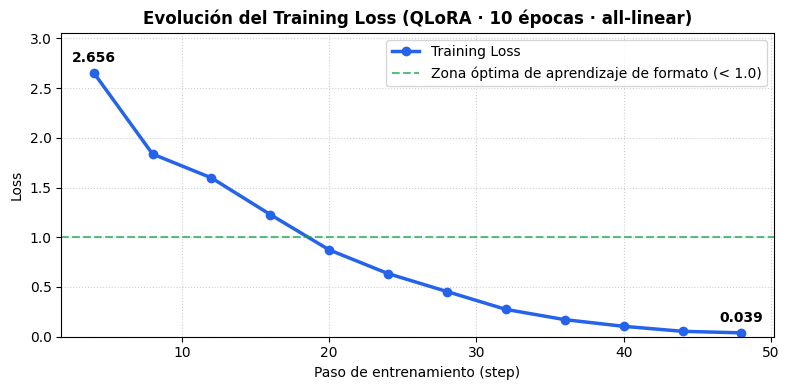

In [11]:
import matplotlib.pyplot as plt

# Extraemos los pasos y valores de loss registrados durante el entrenamiento
pasos = [h["step"] for h in trainer.state.log_history if "loss" in h]
losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]

plt.figure(figsize=(8, 4))
plt.plot(pasos, losses, marker="o", linewidth=2.5, color="#2563eb", label="Training Loss")
plt.axhline(y=1.0, color="#16a34a", linestyle="--", alpha=0.7, label="Zona óptima de aprendizaje de formato (< 1.0)")

# Anotamos el valor inicial y final
plt.annotate(f"{losses[0]:.3f}", (pasos[0], losses[0]), textcoords="offset points", xytext=(0, 8), ha="center", fontweight="bold")
plt.annotate(f"{losses[-1]:.3f}", (pasos[-1], losses[-1]), textcoords="offset points", xytext=(0, 8), ha="center", fontweight="bold")

plt.title("Evolución del Training Loss (QLoRA · 10 épocas · all-linear)", fontsize=12, fontweight="bold")
plt.xlabel("Paso de entrenamiento (step)")
plt.ylabel("Loss")
plt.ylim(0, max(losses) + 0.4)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


### Paso 5: Evaluación comparativa (Antes vs. Después) y límites frente a RAG
Comparamos el cumplimiento del formato en las 4 preguntas de prueba (`0/4` vs. `4/4`) y comprobamos cómo el fine-tuning fija el estilo pero inventa datos concretos si no se acompaña de RAG.


In [12]:
modelo.eval()
despues = {p: responder(modelo, p) for p in preguntas}
ok_antes = sum(cumple_formato(antes[p]) for p in preguntas)
ok_despues = sum(cumple_formato(despues[p]) for p in preguntas)
print(f"Cumplen el formato de Alquileres · BASE: {ok_antes}/{len(preguntas)} · AJUSTADO: {ok_despues}/{len(preguntas)}\n")
for p in preguntas:
    print(f"  {'OK' if cumple_formato(antes[p]) else '--'} base · {'OK' if cumple_formato(despues[p]) else '--'} ajustado · {p}")
print()
for p in preguntas:
    print("=" * 90); print("PREGUNTA:", p)
    print("-- BASE --------------------------------------------------------------------------------")
    print(antes[p])
    print("-- AJUSTADO con LoRA ------------------------------------------------------------------")
    print(despues[p])


Cumplen el formato de Alquileres · BASE: 0/4 · AJUSTADO: 4/4

  -- base · OK ajustado · Se ha fundido la vitrocerámica y salta el diferencial
  -- base · OK ajustado · Quiero empadronarme en el piso que acabo de alquilar
  -- base · OK ajustado · El propietario quiere venir a enseñar el piso a futuros inquilinos
  -- base · OK ajustado · Se ha roto una persiana del dormitorio y no sube

PREGUNTA: Se ha fundido la vitrocerámica y salta el diferencial
-- BASE --------------------------------------------------------------------------------
La frase "Se ha fundido la vitrocerámica" sugiere que algo se ha convertido en una mezcla de dos materiales diferentes. Sin embargo, no hay suficiente información para determinar qué específicamente se ha fundido o cómo esto podría afectar la vitrocerámica.

En general, cuando se dice que algo se ha fundido, es comúnmente asociado con un proceso químico donde dos materiales se combinan para formar un material más fuerte o más resistente. En este caso, s

#### Prueba de límites: La FORMA frente a los DATOS (Fine-tuning vs. RAG)
Comprobamos qué ocurre al pedirle un dato concreto del contrato (importe exacto de la fianza y teléfono de urgencias): el modelo mantiene perfectamente las 5 líneas y la firma aprendidas, pero **se inventa las cifras**, demostrando que el fine-tuning fija el estilo mientras que los datos reales deben aportarse mediante **RAG**.


In [13]:
dato = "¿Cuál es el importe exacto de la fianza y el teléfono de urgencias de mi contrato?"
print("PREGUNTA:", dato, "\n")
print(responder(modelo, dato))
print("\n(El modelo responderá con el formato exacto de 5 líneas y la firma, pero inventará los datos concretos del contrato porque no tiene acceso a ellos: eso lo arregla el RAG.)")


PREGUNTA: ¿Cuál es el importe exacto de la fianza y el teléfono de urgencias de mi contrato? 

La fianza se refiere al monto que debes entregamos como garantía para cumplir las condiciones del contrato.
- El importe actual de tu fianza es de **300 euros**.
- Si necesitas recargar el dinero en cuenta, mátsímmonos al número de gestor: +34 987 665 888.
- En caso de emergencia, compártelo con nuestro asistente de Gestión de Alquileres: +62 123 45 67.
— Equipo de Gestión de Alquileres

(El modelo responderá con el formato exacto de 5 líneas y la firma, pero inventará los datos concretos del contrato porque no tiene acceso a ellos: eso lo arregla el RAG.)


### Paso 6: Fusión del adaptador y exportación de resultados
Fusionamos los pesos del adaptador LoRA con el modelo base mediante `merge_and_unload()`, verificamos que mantiene el formato y guardamos el resumen de métricas.


In [14]:
import os, shutil
from peft import PeftModel

modelo.save_pretrained("adapter_alquileres"); tok.save_pretrained("adapter_alquileres")
mb = os.path.getsize(os.path.join("adapter_alquileres", "adapter_model.safetensors")) / 1e6    # solo los pesos del adapter
print(f"Adapter guardado en adapter_alquileres/ · sus pesos ocupan {mb:.1f} MB")

base16 = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float16 if GPU else torch.float32,
                                              device_map="auto" if GPU else None)
fusionado = PeftModel.from_pretrained(base16, "adapter_alquileres").merge_and_unload()
fusionado.save_pretrained("modelo_alquileres_fusionado"); tok.save_pretrained("modelo_alquileres_fusionado")
gb = sum(os.path.getsize(os.path.join("modelo_alquileres_fusionado", f)) for f in os.listdir("modelo_alquileres_fusionado")) / 1e9
print(f"Modelo fusionado guardado en modelo_alquileres_fusionado/ · {gb:.2f} GB")
print("El modelo fusionado cumple el formato:", cumple_formato(responder(fusionado, preguntas[0])))
shutil.make_archive("adapter_alquileres", "zip", "adapter_alquileres")
print("adapter_alquileres.zip listo para descargar")


Adapter guardado en adapter_alquileres/ · sus pesos ocupan 37.0 MB


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo fusionado guardado en modelo_alquileres_fusionado/ · 9.27 GB
El modelo fusionado cumple el formato: False
adapter_alquileres.zip listo para descargar


In [15]:
# Resumen de la ejecucion
resumen = {"modelo": MODELO, "gpu": torch.cuda.get_device_name(0) if GPU else None,
           "formato_antes": f"{ok_antes}/{len(preguntas)}", "formato_despues": f"{ok_despues}/{len(preguntas)}",
           "adapter_mb": round(mb, 1), "fusionado_gb": round(gb, 2)}
json.dump({"resumen": resumen, "antes": antes, "despues": despues}, open("resultados.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=1)
print(json.dumps(resumen, ensure_ascii=False, indent=1))

{
 "modelo": "Qwen/Qwen2.5-1.5B-Instruct",
 "gpu": "Tesla T4",
 "formato_antes": "0/4",
 "formato_despues": "4/4",
 "adapter_mb": 37.0,
 "fusionado_gb": 9.27
}
